### DNA Methylation (411280 features)
pymaftools: https://github.com/xu62u4u6/pymaftools/blob/main/pymaftools/core/Clustering.py

In [1]:
#conda activate TLS
#pip uninstall pymaftools
#pip install --no-cache-dir git+https://github.com/xu62u4u6/pymaftools.git
from pymaftools import *
import sys
sys.path.append("/home/data/data_YM313112004/TLS_model/utils/")
random_seed = 42

In [2]:
# 不用重啟 kernel，Notebook 就會自動載入更新後的函式
%load_ext autoreload
%autoreload 2

In [26]:
common_samples = np.load("/home/data/data_YM313112004/TLS_model/match_sample/common_samples.npy", allow_pickle=True)

from pymaftools import PivotTable
meth_table = PivotTable.read_sqlite("/home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table_full.sqlite")
all_table = meth_table.subset(samples=common_samples)
all_table

[PivotTable] loaded from /home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table_full.sqlite


sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
cg00000957,0.919397,0.909714,0.939037,0.901546,0.884444,0.868726,0.909582,0.920801,0.929190,0.964897,...,0.872915,0.884958,0.910217,0.897729,0.908713,0.902687,0.889559,0.846592,0.898216,0.936432
cg00001349,0.882533,0.866738,0.799961,0.875664,0.899736,0.802857,0.871314,0.820521,0.878098,0.971284,...,0.752806,0.806740,0.833954,0.832123,0.757777,0.870202,0.812409,0.781593,0.893649,0.914793
cg00001583,0.021885,0.018424,0.016866,0.023278,0.034043,0.027261,0.019225,0.028214,0.169458,0.017440,...,0.029369,0.021620,0.023432,0.026800,0.015751,0.034707,0.020148,0.028720,0.015718,0.078723
cg00002028,0.027313,0.019661,0.021588,0.019659,0.023661,0.018200,0.020213,0.022031,0.021693,0.025581,...,0.020428,0.020901,0.021640,0.022886,0.013067,0.018166,0.017767,0.033958,0.024594,0.020918
cg00002719,0.308909,0.041136,0.032252,0.118069,0.040626,0.040807,0.055265,0.032915,0.027143,0.308583,...,0.049043,0.037740,0.041597,0.042716,0.022427,0.033302,0.025554,0.091153,0.376123,0.035544
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
ch.22.44116734F,0.077411,0.039462,0.264218,0.094812,0.080814,0.063874,0.058787,0.065512,0.192877,0.205568,...,0.045984,0.053295,0.045998,0.131421,0.055014,0.046798,0.059154,0.045225,0.092240,0.038525
ch.22.46830341F,0.023136,0.028516,0.025613,0.023540,0.030614,0.021184,0.026781,0.027070,0.025389,0.035120,...,0.026796,0.029820,0.020426,0.030032,0.028681,0.027758,0.025377,0.023243,0.026059,0.024838
ch.22.1008279F,0.038899,0.040902,0.046655,0.049996,0.046328,0.029406,0.046889,0.030791,0.038734,0.059837,...,0.033647,0.025221,0.017920,0.030363,0.040741,0.039799,0.044258,0.026659,0.053672,0.034907


#### Feature Selection

- Promoter CpGs

In [4]:
value_counts = (
    pd.Series(all_table.feature_metadata["UCSC_RefGene_Group"])
    .dropna()
    .str.split(';')
    .explode()  # 展平 nested list
    .value_counts()
)
print(value_counts)

UCSC_RefGene_Group
Body       247409
TSS1500    106921
5'UTR       90763
TSS200      79803
1stExon     47375
3'UTR       25177
Name: count, dtype: int64


In [5]:
# 找出落在任一 promoter region 的 CpG probes
clean_region = pd.Series(all_table.feature_metadata["UCSC_RefGene_Group"]).dropna()
mask = clean_region.apply(lambda x: any(promo in x.split(';') for promo in ["TSS1500", "TSS200", "5'UTR", "1stExon"]))
promoter_cpg = mask[mask].index.tolist()
print("CpGs in promoter region:", len(promoter_cpg))

# 只取 promoter region probes (175611 probes)
table = all_table.subset(features=promoter_cpg)
table

CpGs in promoter region: 175611


sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
cg00001349,0.882533,0.866738,0.799961,0.875664,0.899736,0.802857,0.871314,0.820521,0.878098,0.971284,...,0.752806,0.806740,0.833954,0.832123,0.757777,0.870202,0.812409,0.781593,0.893649,0.914793
cg00002028,0.027313,0.019661,0.021588,0.019659,0.023661,0.018200,0.020213,0.022031,0.021693,0.025581,...,0.020428,0.020901,0.021640,0.022886,0.013067,0.018166,0.017767,0.033958,0.024594,0.020918
cg00002719,0.308909,0.041136,0.032252,0.118069,0.040626,0.040807,0.055265,0.032915,0.027143,0.308583,...,0.049043,0.037740,0.041597,0.042716,0.022427,0.033302,0.025554,0.091153,0.376123,0.035544
cg00003202,0.010551,0.010802,0.008807,0.009219,0.012252,0.012541,0.011308,0.010550,0.009503,0.009336,...,0.011911,0.010553,0.010166,0.012667,0.008260,0.008679,0.009312,0.020967,0.008069,0.009375
cg00003287,0.079789,0.280611,0.045989,0.155247,0.134850,0.122337,0.074970,0.101558,0.043191,0.085729,...,0.042063,0.188794,0.211763,0.243362,0.077239,0.256867,0.146508,0.095767,0.082345,0.210055
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cg27611781,0.094445,0.072145,0.053846,0.063698,0.055659,0.065773,0.044971,0.063108,0.065519,0.061686,...,0.061899,0.056773,0.058297,0.050725,0.057324,0.060953,0.080017,0.043021,0.085597,0.040123
cg27614432,0.030787,0.032276,0.037162,0.042223,0.035908,0.027262,0.032424,0.031383,0.042807,0.031673,...,0.038832,0.037277,0.036286,0.034660,0.036905,0.031496,0.036090,0.028491,0.043333,0.031876
cg27634071,0.082990,0.158816,0.049407,0.067537,0.055996,0.074497,0.441692,0.059749,0.034160,0.101245,...,0.065043,0.108635,0.068498,0.030570,0.069256,0.088732,0.128004,0.039663,0.508902,0.141647


- Protein Coding

In [6]:
# # 讀入 GTF (只取非註解行)
# gtf = pd.read_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode.v36.annotation.gtf", sep="\t", comment="#", header=None)
# gtf.columns = ["chr","source","feature","start","end","score","strand","phase","additional_info"]

# # 只保留 gene 層級
# gencode = gtf[gtf["feature"] == "gene"].copy()

# # 從 additional_info 欄位解析 gene_type 和 gene_name
# def get_info(attr, key):
#     for entry in attr.split(";"):
#         entry = entry.strip()  # 移除頭尾指定字符
#         if entry.startswith(key + " "):
#             return entry.split(" ")[1].replace('"','')
#     return None

# gencode["gene_id"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_id"))
# gencode["gene_type"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_type"))
# gencode["gene_name"] = gencode["additional_info"].apply(lambda x: get_info(x, "gene_name"))
# gencode["level"] = gencode["additional_info"].apply(lambda x: get_info(x, "level"))
# gencode["hgnc_id"] = gencode["additional_info"].apply(lambda x: get_info(x, "hgnc_id"))
# gencode["havana_gene"] = gencode["additional_info"].apply(lambda x: get_info(x, "havana_gene"))
# gencode.drop(columns=["feature"], inplace=True)
# gencode.to_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode_anno_v36.csv", index=False)

In [7]:
# Protein coding gene list
gencode = pd.read_csv("/home/data/data_YM313112004/TLS_model/data/metadata/gencode_anno_v36.csv", index_col=False)
pc_genes = gencode[gencode["gene_type"] == "protein_coding"]
pc_gene_list = pc_genes["gene_name"].unique().tolist()

# 找出屬於 protein coding 的 CpG probes
clean_gene = pd.Series(table.feature_metadata["UCSC_RefGene_Name"]).dropna()
mask = clean_gene.apply(lambda x: any(pc in x.split(';') for pc in pc_gene_list))
pc_gene_cpg = mask[mask].index.tolist()
print("CpGs (protein coding):", len(pc_gene_cpg))

# 只取 promoter region probes (154359 probes)
table = table.subset(features=pc_gene_cpg)
table

CpGs (protein coding): 154359


sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
cg00001349,0.882533,0.866738,0.799961,0.875664,0.899736,0.802857,0.871314,0.820521,0.878098,0.971284,...,0.752806,0.806740,0.833954,0.832123,0.757777,0.870202,0.812409,0.781593,0.893649,0.914793
cg00002028,0.027313,0.019661,0.021588,0.019659,0.023661,0.018200,0.020213,0.022031,0.021693,0.025581,...,0.020428,0.020901,0.021640,0.022886,0.013067,0.018166,0.017767,0.033958,0.024594,0.020918
cg00003202,0.010551,0.010802,0.008807,0.009219,0.012252,0.012541,0.011308,0.010550,0.009503,0.009336,...,0.011911,0.010553,0.010166,0.012667,0.008260,0.008679,0.009312,0.020967,0.008069,0.009375
cg00003287,0.079789,0.280611,0.045989,0.155247,0.134850,0.122337,0.074970,0.101558,0.043191,0.085729,...,0.042063,0.188794,0.211763,0.243362,0.077239,0.256867,0.146508,0.095767,0.082345,0.210055
cg00007898,0.027989,0.021401,0.022351,0.025229,0.026137,0.022294,0.027878,0.020565,0.021699,0.028770,...,0.021682,0.023310,0.027739,0.019555,0.016071,0.015376,0.014596,0.017133,0.017564,0.025709
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cg27553637,0.043343,0.059384,0.028552,0.044666,0.057133,0.051513,0.032302,0.055115,0.034003,0.029150,...,0.040003,0.053836,0.062831,0.064052,0.047127,0.063154,0.051001,0.035061,0.054692,0.096170
cg27611781,0.094445,0.072145,0.053846,0.063698,0.055659,0.065773,0.044971,0.063108,0.065519,0.061686,...,0.061899,0.056773,0.058297,0.050725,0.057324,0.060953,0.080017,0.043021,0.085597,0.040123
cg27634071,0.082990,0.158816,0.049407,0.067537,0.055996,0.074497,0.441692,0.059749,0.034160,0.101245,...,0.065043,0.108635,0.068498,0.030570,0.069256,0.088732,0.128004,0.039663,0.508902,0.141647


- Sex Chromosome

In [8]:
# Filter sex chromosome genes
clean_table = pd.Series(table.feature_metadata["chr"]).dropna()
mask = clean_table.apply(lambda x: x not in ["chrX", "chrY"])
non_sex_chr = mask[mask].index.tolist()
table = table.subset(features=non_sex_chr)
table

sample,TCGA-2J-AAB1-01A,TCGA-2J-AAB4-01A,TCGA-2J-AAB6-01A,TCGA-2J-AAB8-01A,TCGA-2J-AAB9-01A,TCGA-2J-AABA-01A,TCGA-2J-AABE-01A,TCGA-2J-AABF-01A,TCGA-2J-AABH-01A,TCGA-2J-AABI-01A,...,TCGA-XD-AAUG-01A,TCGA-XD-AAUH-01A,TCGA-XD-AAUI-01A,TCGA-XD-AAUL-01A,TCGA-XN-A8T3-01A,TCGA-XN-A8T5-01A,TCGA-YB-A89D-01A,TCGA-YH-A8SY-01A,TCGA-YY-A8LH-01A,TCGA-Z5-AAPL-01A
feature,,,,,,,,,,,,,,,,,,,,,
cg00001349,0.882533,0.866738,0.799961,0.875664,0.899736,0.802857,0.871314,0.820521,0.878098,0.971284,...,0.752806,0.806740,0.833954,0.832123,0.757777,0.870202,0.812409,0.781593,0.893649,0.914793
cg00002028,0.027313,0.019661,0.021588,0.019659,0.023661,0.018200,0.020213,0.022031,0.021693,0.025581,...,0.020428,0.020901,0.021640,0.022886,0.013067,0.018166,0.017767,0.033958,0.024594,0.020918
cg00003202,0.010551,0.010802,0.008807,0.009219,0.012252,0.012541,0.011308,0.010550,0.009503,0.009336,...,0.011911,0.010553,0.010166,0.012667,0.008260,0.008679,0.009312,0.020967,0.008069,0.009375
cg00003287,0.079789,0.280611,0.045989,0.155247,0.134850,0.122337,0.074970,0.101558,0.043191,0.085729,...,0.042063,0.188794,0.211763,0.243362,0.077239,0.256867,0.146508,0.095767,0.082345,0.210055
cg00007898,0.027989,0.021401,0.022351,0.025229,0.026137,0.022294,0.027878,0.020565,0.021699,0.028770,...,0.021682,0.023310,0.027739,0.019555,0.016071,0.015376,0.014596,0.017133,0.017564,0.025709
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cg27553637,0.043343,0.059384,0.028552,0.044666,0.057133,0.051513,0.032302,0.055115,0.034003,0.029150,...,0.040003,0.053836,0.062831,0.064052,0.047127,0.063154,0.051001,0.035061,0.054692,0.096170
cg27611781,0.094445,0.072145,0.053846,0.063698,0.055659,0.065773,0.044971,0.063108,0.065519,0.061686,...,0.061899,0.056773,0.058297,0.050725,0.057324,0.060953,0.080017,0.043021,0.085597,0.040123
cg27634071,0.082990,0.158816,0.049407,0.067537,0.055996,0.074497,0.441692,0.059749,0.034160,0.101245,...,0.065043,0.108635,0.068498,0.030570,0.069256,0.088732,0.128004,0.039663,0.508902,0.141647


In [9]:
# DMP 定義: p.adj < 0.01 & |deltaBeta| > 0.1 
# dmp_list = dmp_df[dmp_df['changeBeta'].isin(['Hyper', 'Hypo'])].index.tolist()
# print("DMPs:", len(dmp_list))  # 5464 個 DMPs

dmp_list_promoter = table.feature_metadata[table.feature_metadata['changeBeta'].isin(['Hyper', 'Hypo'])].index.tolist()
print("DMPs in promoter region probes:", len(dmp_list_promoter))  # 1641 個 DMPs

DMPs in promoter region probes: 1641


#### Split into train / test dataset
* validation 跟 test dataset 都需要 fit training 的數值

In [10]:
from sklearn.model_selection import train_test_split
X = table.T  # shape: samples × genes
y = table.sample_metadata["TLS"]  # TLS label (0 or 1)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_seed, stratify=y)

# Add train/test labels to sample_metadata and sort
table.sample_metadata.loc[y_train.index, "split_42"] = "train"
table.sample_metadata.loc[y_test.index, "split_42"] = "test"
table = table.reindex(columns=y_train.index.tolist() + y_test.index.tolist())
table

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
feature,,,,,,,,,,,,,,,,,,,,,
cg00001349,0.917385,0.850538,0.866738,0.826886,0.894012,0.798107,0.914773,0.822252,0.864286,0.878935,...,0.875664,0.801732,0.918759,0.829717,0.751265,0.813414,0.870202,0.779287,0.912231,0.929951
cg00002028,0.021231,0.019718,0.019661,0.021103,0.025932,0.021388,0.019564,0.023533,0.015353,0.023734,...,0.019659,0.021683,0.019735,0.016584,0.026457,0.015726,0.018166,0.017022,0.019276,0.028117
cg00003202,0.007963,0.009084,0.010802,0.009520,0.011826,0.010848,0.010273,0.008575,0.008689,0.009425,...,0.009219,0.010983,0.012505,0.008989,0.008967,0.008038,0.008679,0.010825,0.012163,0.009580
cg00003287,0.101517,0.128446,0.280611,0.096589,0.072933,0.126198,0.115828,0.077759,0.113211,0.138763,...,0.155247,0.159876,0.392309,0.067698,0.163522,0.241684,0.256867,0.158618,0.091230,0.174663
cg00007898,0.015036,0.015517,0.021401,0.018276,0.017093,0.019298,0.022117,0.017464,0.018314,0.020540,...,0.025229,0.021778,0.020757,0.018566,0.017519,0.014847,0.015376,0.017363,0.022811,0.019420
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cg27553637,0.035309,0.027913,0.059384,0.062919,0.061258,0.041757,0.028829,0.021529,0.059109,0.057824,...,0.044666,0.056467,0.050405,0.048165,0.038222,0.038417,0.063154,0.053349,0.074400,0.041626
cg27611781,0.053845,0.042588,0.072145,0.099437,0.076965,0.101835,0.048461,0.050811,0.066035,0.068082,...,0.063698,0.067723,0.081307,0.047738,0.089751,0.093075,0.060953,0.076979,0.109801,0.100997
cg27634071,0.087041,0.071946,0.158816,0.074191,0.056376,0.107809,0.045037,0.039516,0.101153,0.178166,...,0.067537,0.129513,0.052504,0.067607,0.077832,0.058504,0.088732,0.055680,0.089156,0.105617


In [22]:
table.to_sqlite(db_path="/home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite")

[PivotTable] saved to /home/data/data_YM313112004/TLS_model/results/PAAD/table/meth_table.sqlite


In [11]:
# 保留在 training validation set 中 high median absolute deviation 的 features
train_samples = table.sample_metadata["split_42"] == "train" 
train_table = table.subset(samples=train_samples)

threshold = 0.1
mad_values = train_table.apply(lambda x: np.median(np.abs(x - np.median(x))), axis=1)
#threshold = np.percentile(mad_values.values, 100 * (1 - top_percent))  # top 10% genes
high_mad_rows = mad_values[mad_values >= threshold].index
train_table = train_table.subset(features=high_mad_rows)
train_table

sample,TCGA-2L-AAQA-01A,TCGA-2L-AAQL-01A,TCGA-2J-AAB4-01A,TCGA-IB-A6UG-01A,TCGA-HZ-A77O-01A,TCGA-3A-A9IL-01A,TCGA-2J-AABO-01A,TCGA-H6-8124-01A,TCGA-IB-A7M4-01A,TCGA-FB-A5VM-01A,...,TCGA-US-A77E-01A,TCGA-IB-A5SQ-01A,TCGA-IB-AAUM-01A,TCGA-FB-AAQ3-01A,TCGA-IB-7887-01A,TCGA-3A-A9IH-01A,TCGA-F2-A7TX-01A,TCGA-HZ-7924-01A,TCGA-IB-7890-01A,TCGA-IB-7654-01A
feature,,,,,,,,,,,,,,,,,,,,,
cg00046625,0.380233,0.343126,0.262419,0.339897,0.018853,0.021660,0.347730,0.546205,0.347361,0.377705,...,0.371895,0.339493,0.035969,0.363792,0.441921,0.371530,0.116206,0.176468,0.432149,0.419561
cg00095594,0.481911,0.531469,0.090134,0.453692,0.028210,0.027881,0.528701,0.543635,0.019464,0.049682,...,0.407485,0.072750,0.207420,0.499836,0.021438,0.481426,0.235930,0.038456,0.497598,0.357369
cg00152008,0.456948,0.350360,0.285146,0.353477,0.500137,0.038375,0.405152,0.712338,0.460974,0.369384,...,0.389120,0.333227,0.205133,0.380234,0.381377,0.465585,0.368745,0.109050,0.422378,0.413216
cg00290506,0.523788,0.433406,0.245552,0.454376,0.017139,0.016013,0.459220,0.032461,0.407025,0.018809,...,0.425573,0.254170,0.098338,0.391423,0.484367,0.490913,0.018068,0.191471,0.479706,0.059468
cg00426822,0.204246,0.699365,0.520222,0.507026,0.554719,0.917681,0.289195,0.203714,0.248986,0.350097,...,0.305693,0.499425,0.796774,0.430189,0.436113,0.452336,0.681183,0.587135,0.268818,0.361040
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cg24060451,0.498922,0.395422,0.073509,0.205868,0.083812,0.031167,0.354950,0.552707,0.397359,0.274797,...,0.277726,0.296353,0.231291,0.310279,0.287848,0.435310,0.208514,0.217879,0.435922,0.279394
cg25044876,0.418808,0.386782,0.172725,0.325573,0.303681,0.157883,0.379855,0.101528,0.407795,0.360669,...,0.078288,0.376779,0.400849,0.290965,0.117136,0.107829,0.353035,0.274450,0.195044,0.400036
cg25127852,0.486077,0.611264,0.210320,0.151292,0.494744,0.543545,0.503898,0.134413,0.440264,0.218848,...,0.373227,0.395561,0.296157,0.437616,0.224216,0.685427,0.349707,0.397613,0.359550,0.375706


Threshold of MAD: 0.1
Number of selected features: 9179


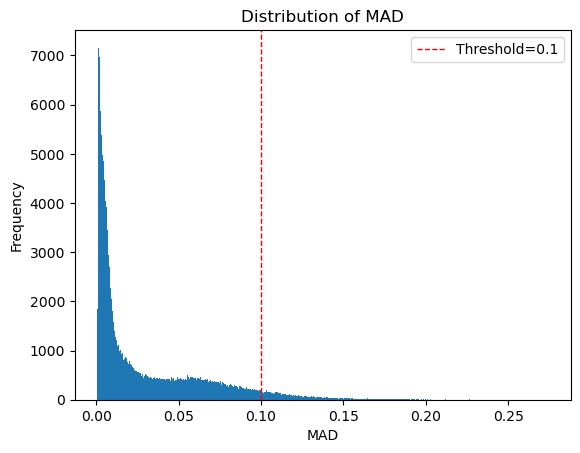

In [17]:
print("Threshold of MAD:", threshold)
print("Number of selected features:", len(mad_values[mad_values >= threshold].index))

import matplotlib.pyplot as plt
plt.hist(mad_values, bins=500)
plt.xlabel("MAD")
plt.ylabel("Frequency")
plt.title("Distribution of MAD")
plt.axvline(threshold, color='red', linestyle='--', label=f'Threshold={threshold}', linewidth=1)
plt.legend()
plt.show()

In [18]:
# 確認 Top 10% genes 中有多少是 DMPs
dmp_counts = (
    pd.Series(train_table.feature_metadata["changeBeta"])
    .dropna()
    .value_counts()
)
print(dmp_counts)

changeBeta
NOT      8201
Hyper     753
Hypo      225
Name: count, dtype: int64


In [12]:
# 套用在 testing set
test_samples = table.sample_metadata["split_42"] == "test" 
test_table = table.subset(samples=test_samples)

test_table = test_table.subset(features=high_mad_rows)
test_table

sample,TCGA-IB-7646-01A,TCGA-IB-AAUU-01A,TCGA-2L-AAQI-01A,TCGA-3A-A9IV-01A,TCGA-3A-A9IU-01A,TCGA-US-A77J-01A,TCGA-US-A77G-01A,TCGA-YY-A8LH-01A,TCGA-2J-AAB6-01A,TCGA-FB-AAPQ-01A,...,TCGA-2J-AAB8-01A,TCGA-IB-7645-01A,TCGA-OE-A75W-01A,TCGA-IB-7644-01A,TCGA-HV-A5A5-01A,TCGA-IB-A7LX-01A,TCGA-XN-A8T5-01A,TCGA-RB-AA9M-01A,TCGA-2J-AABR-01A,TCGA-3A-A9IO-01A
feature,,,,,,,,,,,,,,,,,,,,,
cg00046625,0.418913,0.496136,0.292280,0.019705,0.386635,0.023587,0.351652,0.385354,0.507561,0.281328,...,0.271032,0.235461,0.339636,0.312461,0.164343,0.453959,0.154748,0.126592,0.042962,0.016420
cg00095594,0.019789,0.319113,0.086396,0.049294,0.017103,0.044074,0.485963,0.585777,0.040136,0.479215,...,0.455044,0.363567,0.573302,0.147299,0.023863,0.543267,0.041132,0.233157,0.028622,0.023443
cg00152008,0.417649,0.490245,0.296420,0.272485,0.360397,0.071081,0.467700,0.489671,0.601616,0.305430,...,0.243713,0.252232,0.432211,0.416827,0.158212,0.495930,0.168073,0.242993,0.127483,0.033322
cg00290506,0.462179,0.018782,0.397319,0.015458,0.017574,0.023382,0.428475,0.505613,0.520937,0.382856,...,0.395960,0.313194,0.475641,0.368222,0.363514,0.487010,0.234244,0.017321,0.021779,0.013066
cg00426822,0.494272,0.542928,0.558373,0.937025,0.524642,0.556194,0.807680,0.581176,0.428956,0.627436,...,0.209538,0.567254,0.288688,0.104988,0.656514,0.587959,0.569604,0.628078,0.703441,0.860222
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cg24060451,0.411635,0.492854,0.184021,0.030629,0.065318,0.039964,0.386052,0.512861,0.470647,0.457381,...,0.311963,0.205993,0.519889,0.392521,0.251723,0.540751,0.218753,0.250089,0.080452,0.037348
cg25044876,0.180646,0.234211,0.416780,0.155353,0.305772,0.386892,0.262525,0.419212,0.131165,0.442121,...,0.236734,0.360700,0.457551,0.125677,0.221538,0.316815,0.394693,0.226618,0.381710,0.631594
cg25127852,0.333883,0.608862,0.488028,0.891952,0.689677,0.141313,0.552671,0.524356,0.175145,0.683771,...,0.566157,0.162479,0.516499,0.165521,0.360466,0.801473,0.224383,0.402796,0.349292,0.754238


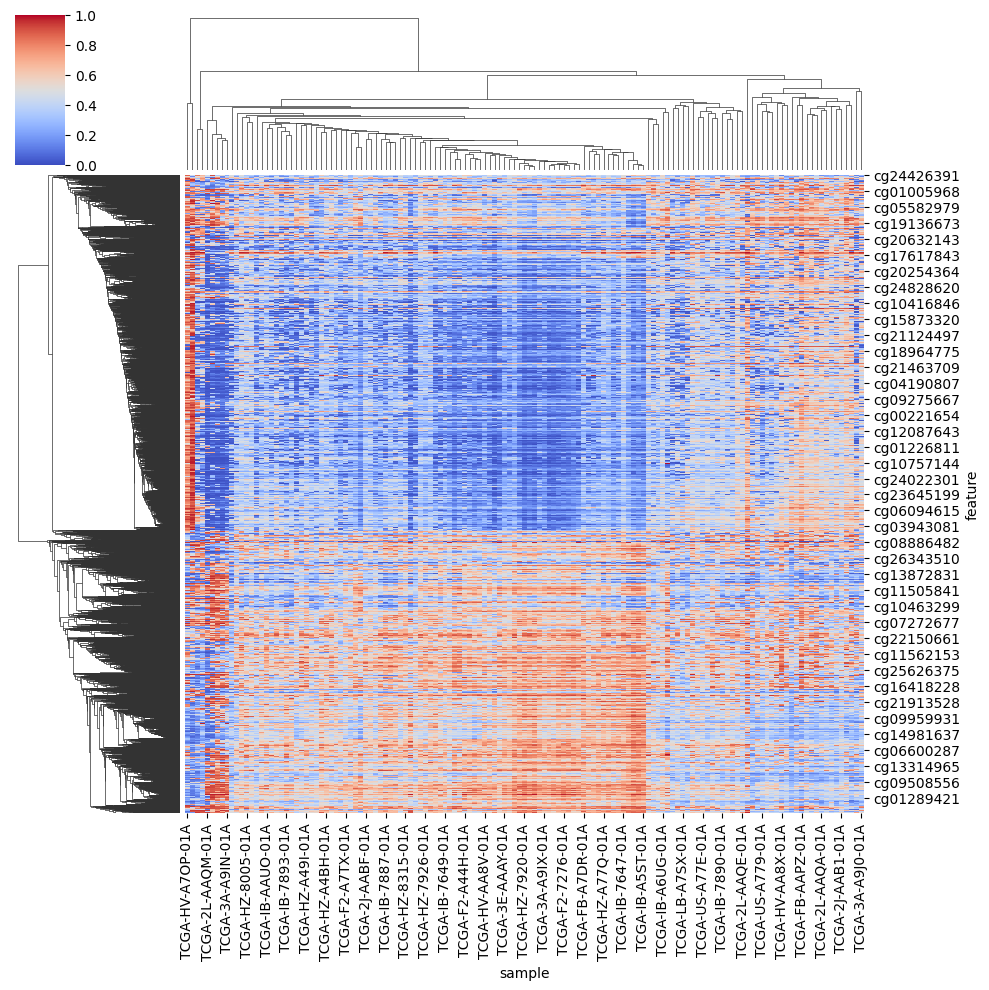

In [16]:
import seaborn as sns
# 用 correlation 距離來計算 clustering，用原始資料來上色
sns.clustermap(train_table, cmap="coolwarm", metric="correlation", cbar_pos=(0.02, 0.83, 0.05, 0.15))

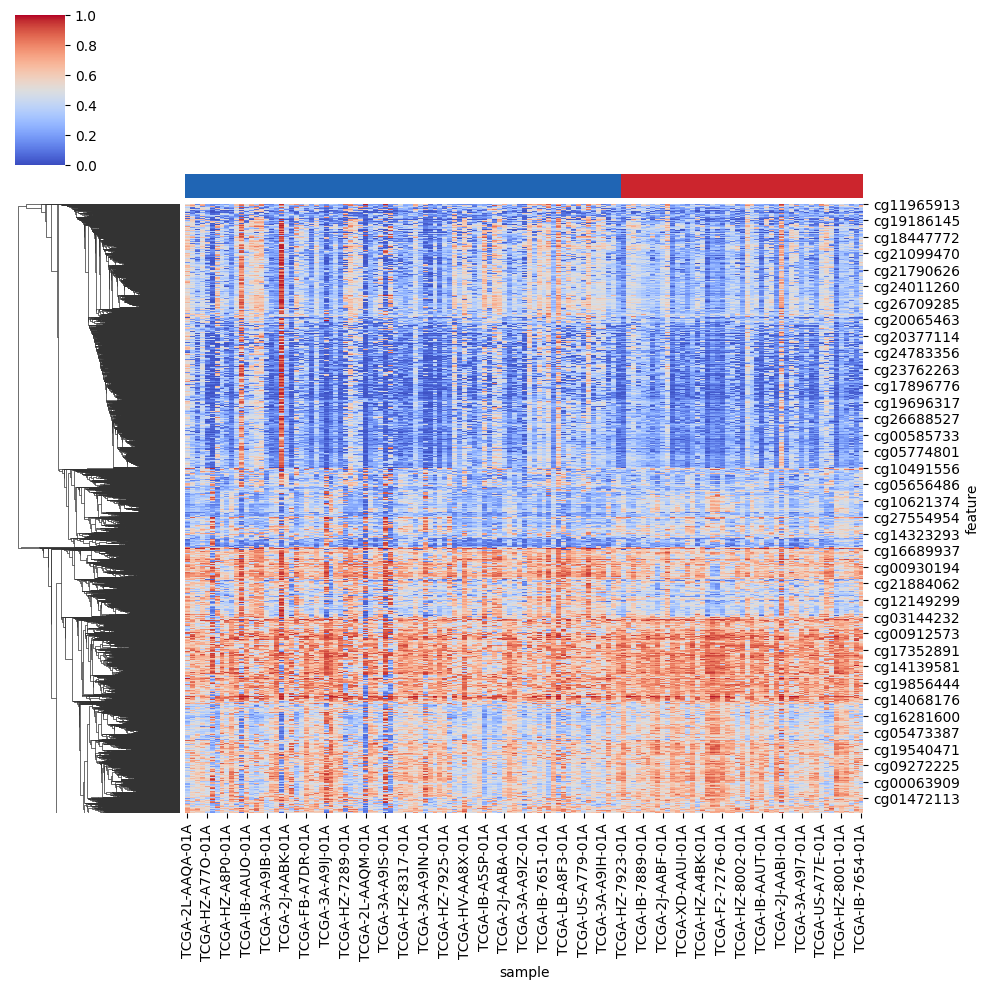

In [17]:
from matplotlib.colors import ListedColormap
tls_labels = train_table.sample_metadata["TLS"].values
unique_tls = sorted(set(tls_labels))
tls_colors = ListedColormap(["#2065B4", "#CC252D"][:len(unique_tls)])  # 自定義顏色

# 根據 TLS 標籤排序列
sorted_indices = np.argsort(tls_labels)
train_table_sorted = train_table.iloc[:, sorted_indices]
sorted_tls_labels = tls_labels[sorted_indices]

sns.clustermap(train_table_sorted, cmap="coolwarm", cbar_pos=(0.02, 0.83, 0.05, 0.15), 
               col_cluster=False, col_colors=tls_colors(sorted_tls_labels))

/home/YM313112004/miniconda3/envs/TLS/lib/python3.12/site-packages/pymaftools/core/PivotTable.py:779: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  merged.feature_metadata = merged_feature_meta.fillna(


<Axes: xlabel='sample', ylabel='feature'>

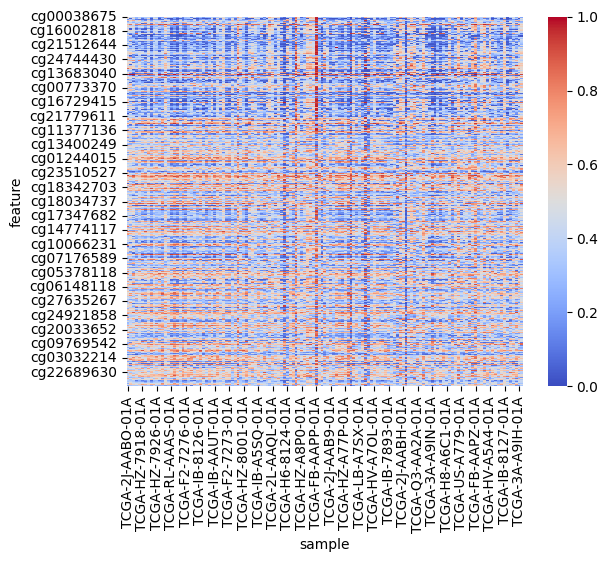

In [18]:
sns.heatmap(train_table.order(group_col="TLS", group_order=[1, 0]), cmap="coolwarm")

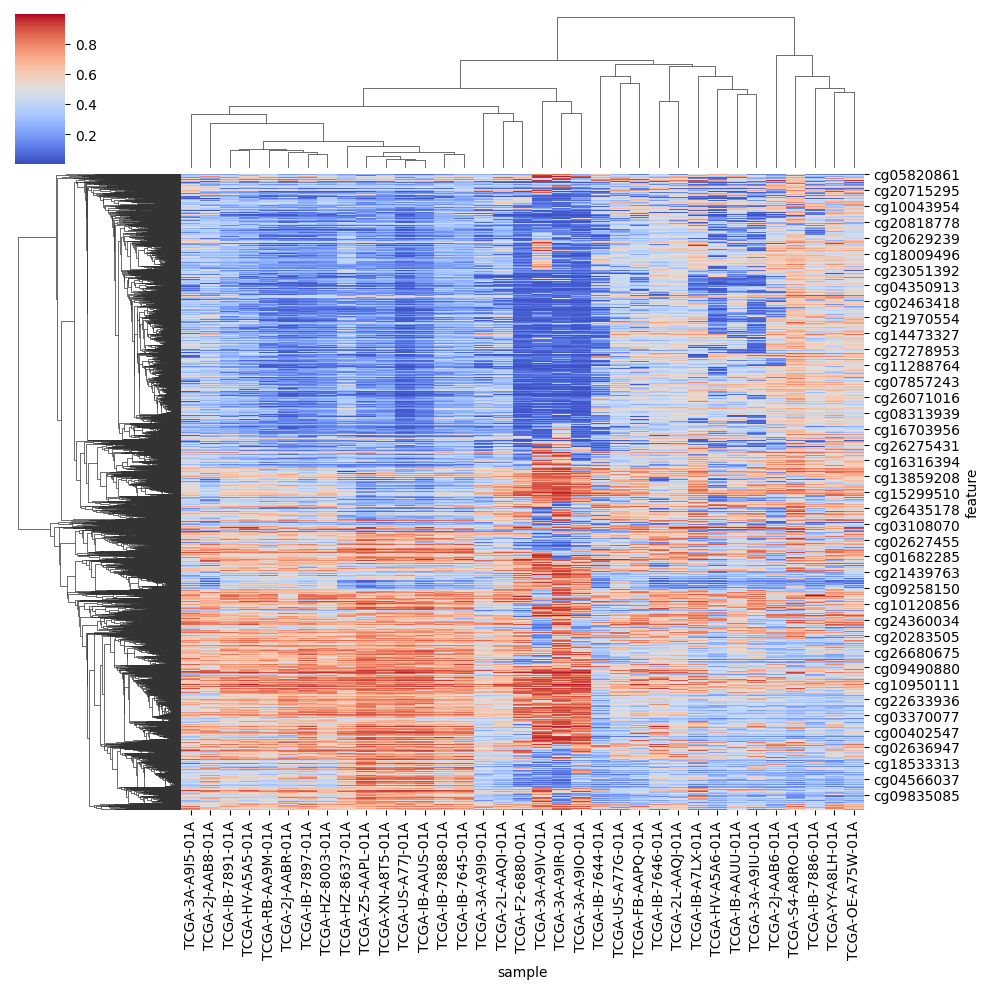

In [19]:
import seaborn as sns
# 用 correlation 距離來計算 clustering，用原始資料來上色
sns.clustermap(test_table, cmap="coolwarm", metric="correlation", cbar_pos=(0.02, 0.83, 0.05, 0.15))

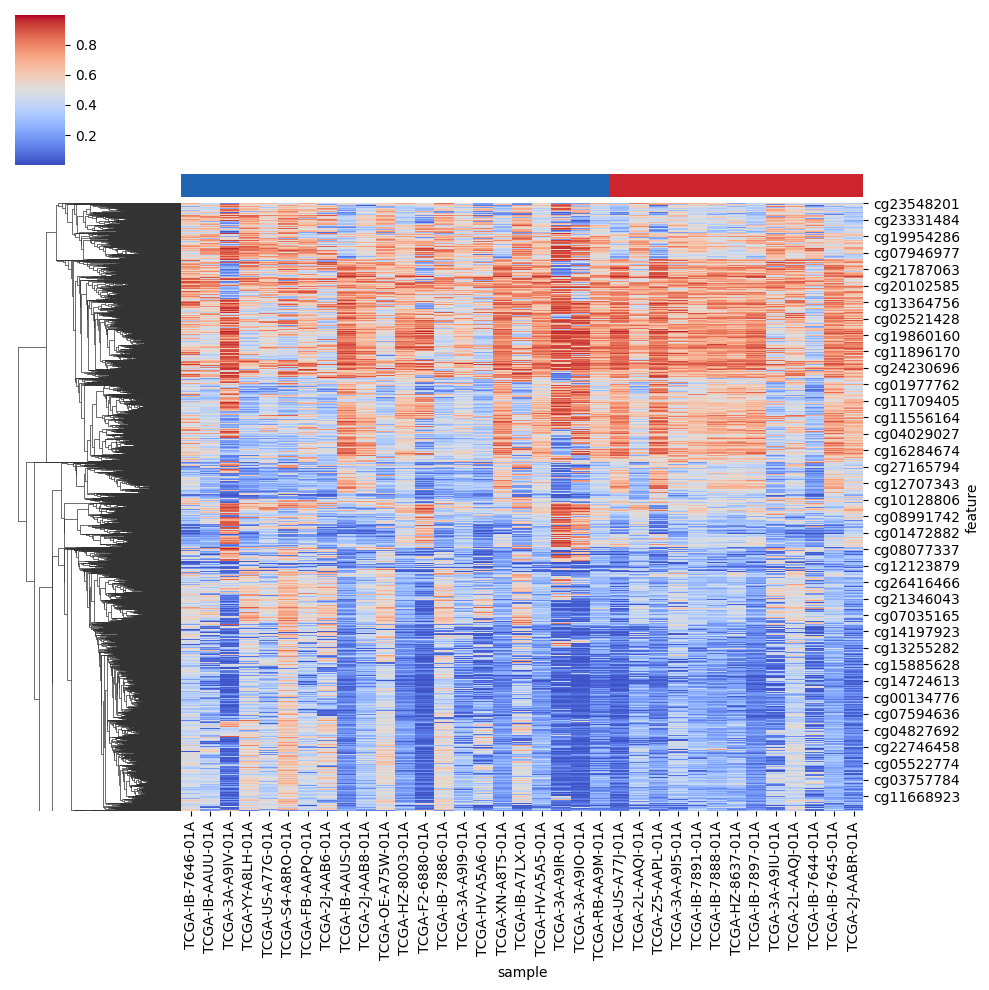

In [20]:
from matplotlib.colors import ListedColormap
tls_labels = test_table.sample_metadata["TLS"].values
unique_tls = sorted(set(tls_labels))
tls_colors = ListedColormap(["#2065B4", "#CC252D"][:len(unique_tls)])  # 自定義顏色

# 根據 TLS 標籤排序列
sorted_indices = np.argsort(tls_labels)
test_table_sorted = test_table.iloc[:, sorted_indices]
sorted_tls_labels = tls_labels[sorted_indices]

sns.clustermap(test_table_sorted, cmap="coolwarm", cbar_pos=(0.02, 0.83, 0.05, 0.15), 
               col_cluster=False, col_colors=tls_colors(sorted_tls_labels))

/home/YM313112004/miniconda3/envs/TLS/lib/python3.12/site-packages/pymaftools/core/PivotTable.py:779: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  merged.feature_metadata = merged_feature_meta.fillna(


<Axes: xlabel='sample', ylabel='feature'>

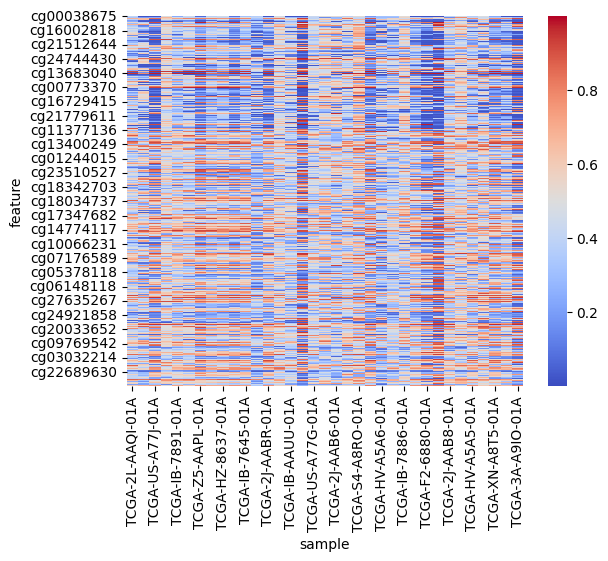

In [21]:
sns.heatmap(test_table.order(group_col="TLS", group_order=[1, 0]), cmap="coolwarm")

In [ ]:
# All features performance
all_features = train_table.index
from model_utils import evaluate_model
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(train_table, test_table, top_features=all_features)
print(report)

/home/YM313112004/miniconda3/envs/TLS/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Selected top 15436 features
F1-score in train set: 1.0
Accuracy in train set: 1.0
AUC in train set: 1.0
F1-score in test set: 0.56
Accuracy in test set: 0.6857142857142857
AUC in test set: 0.7587412587412588


#### mRMR

In [ ]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from mrmr import mrmr_classif
from sklearn.metrics import roc_auc_score

X = pd.DataFrame(train_table.T)
y = pd.Series(train_table.sample_metadata.loc[train_table.columns]["TLS"])
K_list = [50, 75, 100, 150, 200, 250, 300, 350, 400]  # 你要選的特徵數

outer_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
auc_scores = []
std_auc_scores = []
best_auc = 0
best_k = None

for K in K_list:
    auc_scores_K = []
    for train_idx, val_idx in outer_cv.split(X, y):
        X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
        y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]
        
        # 只用 training fold 做 mRMR
        selected_features = mrmr_classif(X=X_train, y=y_train, K=K)
        X_train_sel = X_train[selected_features]
        X_val_sel = X_val[selected_features]
        
        clf = RandomForestClassifier(
            n_estimators=300,
            max_depth=5,
            min_samples_split=10,
            min_samples_leaf=5,
            class_weight="balanced",
            random_state=42,
            n_jobs=10
        )
        clf.fit(X_train_sel, y_train)
        auc = roc_auc_score(y_val, clf.predict_proba(X_val_sel)[:,1])
        auc_scores_K.append(auc)
    
    mean_auc = np.mean(auc_scores_K)
    std_auc = np.std(auc_scores_K)
    auc_scores.append(mean_auc)
    std_auc_scores.append(std_auc)
    print(f"K={K}, mean AUC={mean_auc:.3f}, std={std_auc:.3f}")
    
    if mean_auc > best_auc:
        best_auc = mean_auc
        best_k = K

print(f"Best K: {best_k}, AUC: {best_auc:.3f}")

100%|██████████| 50/50 [00:28<00:00,  1.76it/s]


K=50, mean AUC=0.721, std=0.137


100%|██████████| 75/75 [00:41<00:00,  1.79it/s]


K=75, mean AUC=0.731, std=0.125


100%|██████████| 100/100 [00:54<00:00,  1.84it/s]


...

K=300, mean AUC=0.723, std=0.146


100%|██████████| 350/350 [03:19<00:00,  1.76it/s]


K=350, mean AUC=0.721, std=0.143


100%|██████████| 400/400 [03:45<00:00,  1.77it/s]


K=400, mean AUC=0.725, std=0.140
Best K: 100, AUC: 0.736


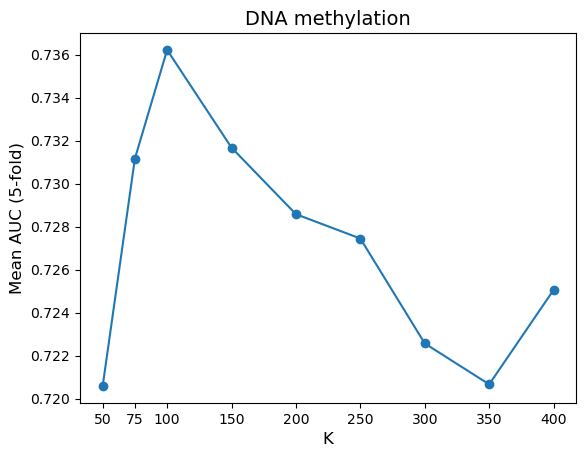

In [ ]:
plt.plot(K_list, auc_scores, '-o')
plt.xlabel("K", fontsize=12)
plt.ylabel("Mean AUC (5-fold)", fontsize=12)
plt.xticks(K_list)
plt.title("DNA methylation", fontsize=14)
plt.savefig("/home/data/data_YM313112004/TLS_model/tiff_figure/paper/mRMR_meth.tiff", dpi=300, format='tiff', bbox_inches='tight', pil_kwargs={'compression': 'tiff_lzw'})
plt.show()

Text(0.5, 1.0, 'Mean AUC with Std (5-fold)')

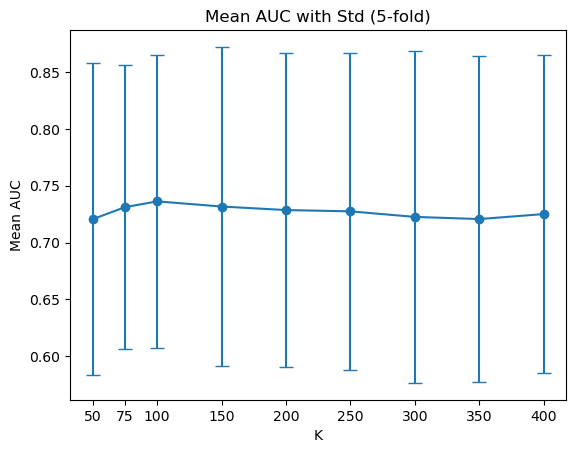

In [22]:
plt.errorbar(K_list, auc_scores, yerr=std_auc_scores, fmt='-o', capsize=5)
plt.xlabel("K")
plt.ylabel("Mean AUC")
plt.xticks(K_list)
plt.title("Mean AUC with Std (5-fold)")

In [23]:
from mrmr import mrmr_classif

top_features = mrmr_classif(
    X=pd.DataFrame(train_table.T),
    y=pd.Series(train_table.sample_metadata.loc[train_table.columns]["TLS"]),
    K=best_k  # 要選幾個
)

np.save("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_meth_mrmr.npy", top_features)
print(top_features) 

100%|██████████| 100/100 [00:56<00:00,  1.78it/s]

['cg01560900', 'cg25473438', 'cg07581732', 'cg20995778', 'cg16829924', 'cg14043752', 'cg25279553', 'cg14947478', 'cg09775841', 'cg20094837', 'cg00929635', 'cg01808708', 'cg04675542', 'cg19083407', 'cg27510066', 'cg01709766', 'cg06704455', 'cg01994308', 'cg01573501', 'cg18322510', 'cg09283223', 'cg20466478', 'cg04222582', 'cg16411361', 'cg20100745', 'cg20707765', 'cg08200621', 'cg18046677', 'cg14387505', 'cg03340964', 'cg22272888', 'cg25548984', 'cg26065909', 'cg15244874', 'cg01546047', 'cg04859929', 'cg19540471', 'cg07569918', 'cg26348243', 'cg09490880', 'cg24520381', 'cg12303318', 'cg08256536', 'cg02343823', 'cg17936488', 'cg02280859', 'cg13046608', 'cg11809958', 'cg14852276', 'cg14993486', 'cg09247319', 'cg17720013', 'cg23182840', 'cg23841470', 'cg19264170', 'cg12970937', 'cg13941760', 'cg23979520', 'cg05007997', 'cg14830003', 'cg09805403', 'cg02647265', 'cg14664412', 'cg13261802', 'cg24486037', 'cg10648815', 'cg14684937', 'cg12626589', 'cg18450931', 'cg15114672', 'cg24658737', 'cg07

#### Feature Importance (Run 100 times)

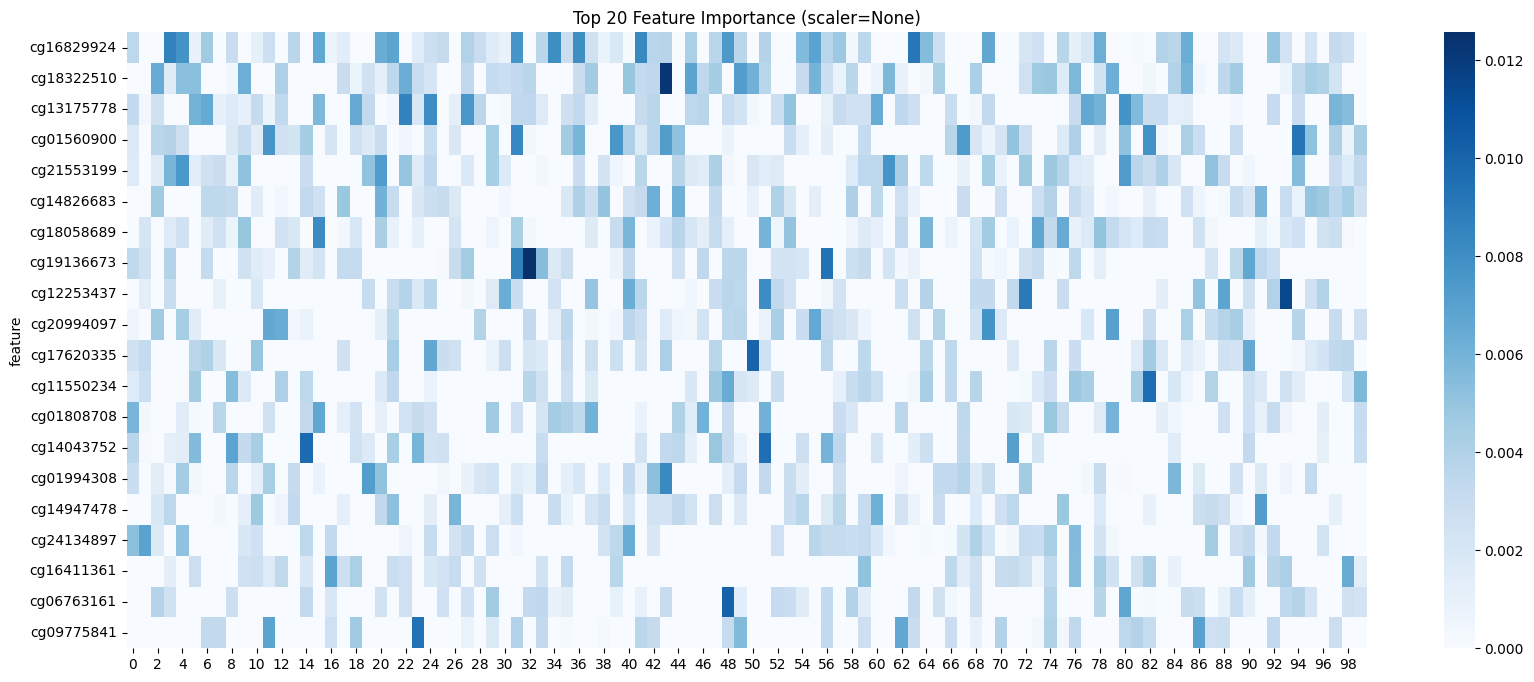

feature
cg16829924    0.002484
cg18322510    0.002255
cg13175778    0.002035
cg01560900    0.001895
cg21553199    0.001768
cg14826683     0.00157
cg18058689    0.001534
cg19136673    0.001452
cg12253437    0.001436
cg20994097    0.001397
cg17620335     0.00133
cg11550234    0.001324
cg01808708    0.001322
cg14043752    0.001263
cg01994308    0.001224
cg14947478    0.001219
cg24134897    0.001218
cg16411361    0.001198
cg06763161    0.001183
cg09775841     0.00116
dtype: object


In [ ]:
from model_utils import run_feature_importance
global_importance = run_feature_importance(train_table, run_seeds=100,
                                           save_path="/home/data/data_YM313112004/TLS_model/results/PAAD/importance_df/meth_importance.csv", plot_top=20)
print(global_importance.head(20))

#### Choose cutoff for selected features

In [15]:
import pandas as pd
importance_df = pd.read_csv("/home/data/data_YM313112004/TLS_model/results/PAAD/importance_df/meth_importance.csv", index_col=0)
global_importance = importance_df.mean(axis=1).sort_values(ascending=False)
global_importance = global_importance.astype(object)   # 將資料型別轉換為 object (防止 knee_x 出現小數點)
print(global_importance.head(20))

feature
cg16829924    0.002484
cg18322510    0.002255
cg13175778    0.002035
cg01560900    0.001895
cg21553199    0.001768
cg14826683     0.00157
cg18058689    0.001534
cg19136673    0.001452
cg12253437    0.001436
cg20994097    0.001397
cg17620335     0.00133
cg11550234    0.001324
cg01808708    0.001322
cg14043752    0.001263
cg01994308    0.001224
cg14947478    0.001219
cg24134897    0.001218
cg16411361    0.001198
cg06763161    0.001183
cg09775841     0.00116
dtype: object


/home/YM313112004/miniconda3/envs/TLS/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Elbow point (Feature top n): 427


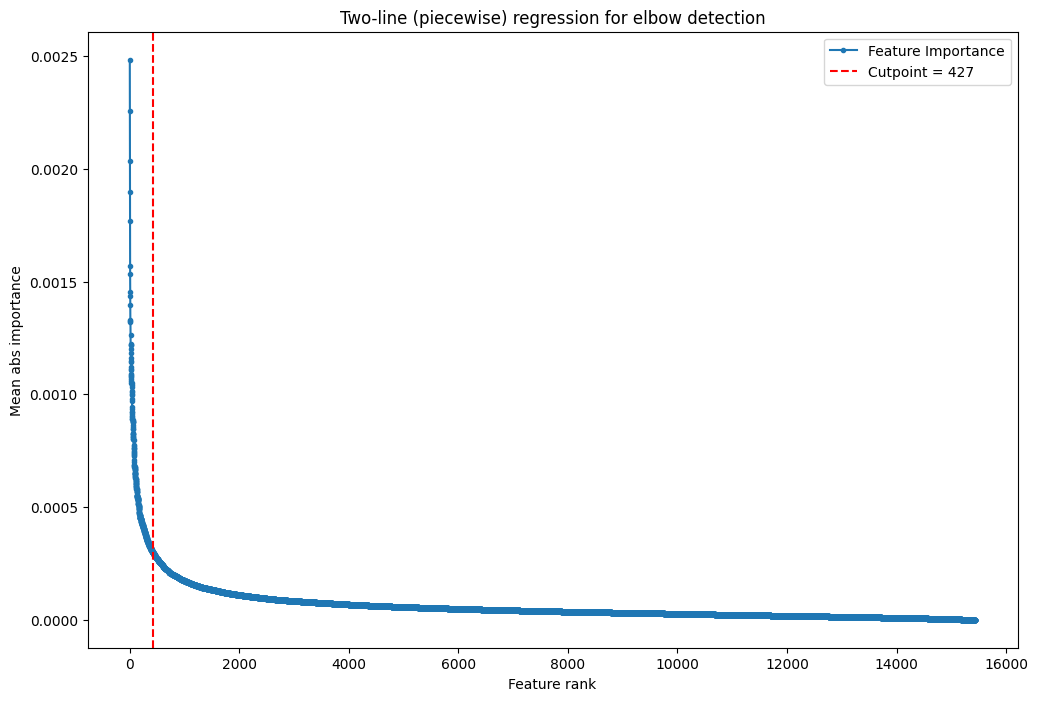

In [16]:
from model_utils import two_line_elbow
knee_x, rss = two_line_elbow(global_importance)

In [17]:
top_features = global_importance.head(knee_x).index
#np.save("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_meth.npy", top_features)
print(top_features)

# top_features = np.load("/home/data/data_YM313112004/TLS_model/results/PAAD/selected_features/top_features_meth.npy", allow_pickle=True)
# top_features

Index(['cg16829924', 'cg18322510', 'cg13175778', 'cg01560900', 'cg21553199',
       'cg14826683', 'cg18058689', 'cg19136673', 'cg12253437', 'cg20994097',
       ...
       'cg03327403', 'cg21578207', 'cg02799411', 'cg16441044', 'cg06363129',
       'cg13844922', 'cg26111327', 'cg15241708', 'cg19371339', 'cg00574819'],
      dtype='object', name='feature', length=427)


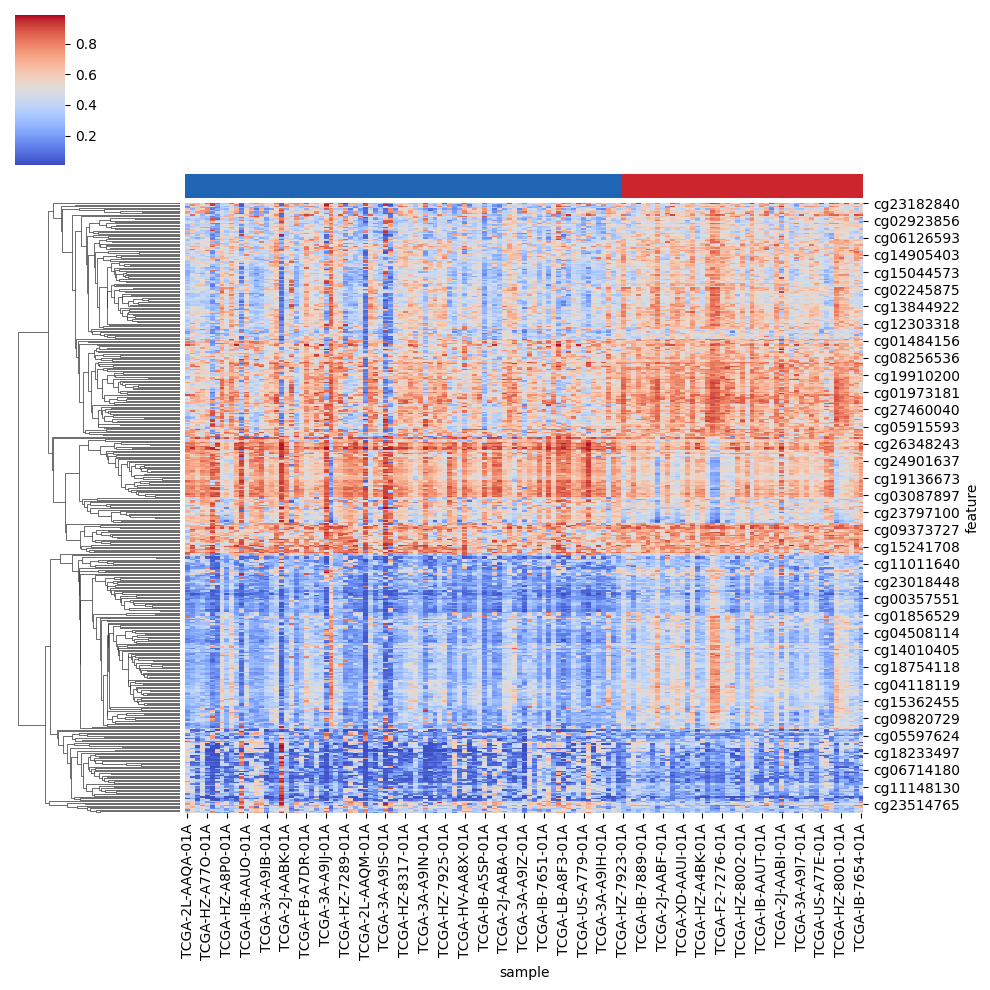

In [27]:
from matplotlib.colors import ListedColormap

# 提取 TLS 標籤並創建顏色分類
train_subseted = train_table.subset(features=top_features)
tls_labels = train_subseted.sample_metadata["TLS"].values
unique_tls = sorted(set(tls_labels))
tls_colors = ListedColormap(["#2065B4", "#CC252D"][:len(unique_tls)])  # 自定義顏色

# 根據 TLS 標籤排序列
sorted_indices = np.argsort(tls_labels)
train_subseted_sorted = train_subseted.iloc[:, sorted_indices]
sorted_tls_labels = tls_labels[sorted_indices]

sns.clustermap(train_subseted_sorted, cmap="coolwarm", cbar_pos=(0.02, 0.83, 0.05, 0.15), 
               col_cluster=False, col_colors=tls_colors(sorted_tls_labels))

In [28]:
train_table.subset(features=top_features).feature_metadata

,AddressA,AddressB,Color,CpG_maf,CpG_rs,DHS,DMR,Enhancer,Forward_Sequence,HMM_Island,...,changeBeta,chr,delta_beta,f,intercept,logFC,pos,pval,qval,strand
feature,,,,,,,,,,,,,,,,,,,,,
cg16829924,48698301,64800418.0,Red,None,None,NaN,None,1.0,ATGCTAAGGTGCTGGGCTATTGACAGTTTCACACATCACCCTTGGC...,None,...,Hyper,chr11,0.147952,25.888530,0.533875,0.352903,36383991,9.217317e-07,3.435147e-05,-
cg18322510,45762305,41753342.0,Red,None,None,NaN,None,NaN,CCCACACGCAGGATAACTGGCGAGTGACGCGGAGTGGCTGCGAGTC...,1:234753221-234754607,...,Hyper,chr1,0.157808,41.643431,0.254386,0.696303,236686618,1.026607e-09,4.151170e-07,-
cg13175778,25643395,NaN,None,None,None,1.0,None,NaN,CTGGTAAGGCCCCACCACGTACCCCAGTCACGTAGTCTCTAAAACT...,None,...,Hyper,chr17,0.129338,35.311714,0.286965,0.536759,202759,1.470596e-08,2.065763e-06,-
cg01560900,71755371,NaN,None,None,None,NaN,None,NaN,GGTTTCTCCCCTTCCTGGGAAGCTGTAATAACCCACAACCAGCCTA...,None,...,Hyper,chr1,0.151141,54.009603,0.334864,0.537396,241804128,7.195385e-12,6.772013e-08,+
cg21553199,43707396,NaN,None,None,None,NaN,None,NaN,ATCAATAGATAGGTGCTTTTCAGGTTGGAATGTTTCCTAGAGTTAT...,None,...,Hyper,chr8,0.104050,28.800190,0.643602,0.216199,22527157,2.504725e-07,1.375417e-05,-
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
cg13844922,73650325,NaN,None,None,None,NaN,None,1.0,CACCTGTAAGTGCTGTTTGAACAAGGAGGTTGCTCCTCCTATTAAC...,None,...,Hyper,chr14,0.129000,21.492507,0.489058,0.337737,65409659,6.898574e-06,1.469787e-04,-
cg26111327,36648306,NaN,None,None,None,NaN,None,NaN,TTAAAATGAACATAACACACAGATCTGATGAAGTTGTCCGGTTAAC...,None,...,NOT,chr3,0.067821,10.903782,0.731126,0.127980,195164931,1.162201e-03,6.514431e-03,-
cg15241708,18795451,NaN,None,None,None,NaN,None,NaN,GTGGTATGTTAACTTACTCTTCTTTGTATAATTGAGGAAGGAATAA...,None,...,NOT,chr5,0.040835,2.516488,0.670345,0.085310,179920582,1.144562e-01,1.297866e-01,+


In [29]:
selected_type = (
    pd.Series(train_table.subset(features=top_features).feature_metadata['changeBeta'])
    .dropna()
    .str.split(';')
    .explode()  # 展平 nested list
    .value_counts()
)
print(selected_type)

changeBeta
NOT      200
Hyper    187
Hypo      40
Name: count, dtype: int64


#### Model Evaluation

In [24]:
# Evaluation on test dataset
from model_utils import evaluate_model
report, y_train, y_pred_prob, y_test, y_test_pred_prob, best_cutoff = evaluate_model(train_table, test_table, top_features=top_features)
print(report)

Selected top 100 features
Best cutoff in AUROC: 0.64
Train | F1-score: 1.000 | Accuracy: 1.000 | AUC: 1.000 | AUPRC: 1.000
Test  | F1-score: 0.522 | Accuracy: 0.686 | AUC: 0.783 | AUPRC: 0.694
              precision    recall  f1-score   support

TLS-negative      0.720     0.818     0.766        22
TLS-positive      0.600     0.462     0.522        13

    accuracy                          0.686        35
   macro avg      0.660     0.640     0.644        35
weighted avg      0.675     0.686     0.675        35

